# Griffiths et al. 2021 — Breast Cancer · 04 EMT-TF Expression
Unconditional final step (outside the gate chain). Score a widened EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families, VIM excluded — it is a mesenchymal marker, not a TF), gate on detectable expression, and overlay the two most pseudotime-informative factors as a categorical thresholded-expresser overlay on the grey manifold.

In [1]:
%matplotlib inline
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 91802 | pseudotime range 0.0 -> 8.07


### Panel scan — detection-gated, sorted by pseudotime correlation

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
print('\nexpressed (frac>0.03):', list(ok.TF))
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'derived pair: {early_tf} (early/root=Gast/pSom origin) <-> {late_tf} (late/terminus=Crest)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.004       0.003      0.001    -0.004    EARLY(root)
 FOXC2      0.000       0.000      0.000     0.003 LATE(terminus)
 FOXC1      0.006       0.004      0.004     0.005 LATE(terminus)
 SNAI1      0.002       0.001      0.001     0.005 LATE(terminus)
 PRRX2      0.017       0.011      0.009     0.014    EARLY(root)
  ZEB2      0.053       0.041      0.032     0.015    EARLY(root)
 PRRX1      0.047       0.034      0.028     0.017    EARLY(root)
TWIST2      0.008       0.005      0.005     0.020 LATE(terminus)
TWIST1      0.018       0.010      0.011     0.025 LATE(terminus)
  ZEB1      0.093       0.064      0.061     0.036    EARLY(root)

expressed (frac>0.03): ['ZEB2', 'PRRX1', 'ZEB1']
derived pair: ZEB2 (early/root=Gast/pSom origin) <-> ZEB1 (late/terminus=Crest)


### Figure — categorical thresholded-expresser overlay on the grey manifold

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.895, 'ZEB1': 0.902} | cells shown: {'ZEB2': 1219, 'ZEB1': 2123}
ZEB2: 5.3% expressing; 1219 shown (upper quartile), mean pseudotime of shown cells = 0.39 (all = 0.55)
ZEB1: 9.3% expressing; 2123 shown (upper quartile), mean pseudotime of shown cells = 0.45 (all = 0.55)
saved expression.pdf


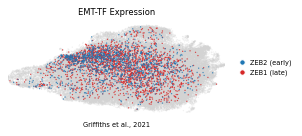

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=f'{early_tf} (early)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=f'{late_tf} (late)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')